# Dr.Copper v2 - Phase 1: Data pipeline, PCA and KMeans

In [1]:
import warnings

import plotly.io as pio

import dr_copper_v2 as dc

pio.renderers.default = "plotly_mimetype+png"

warnings.filterwarnings("ignore")

Download the initial training and development history only.

Fixed split:

| Portion | Dates |
|---|---|
| Warm-up | 2011-11-15 through 2011-12-31 |
| Data1: initial training | 2012-01-01 through 2016-12-31 |
| Data2: development | 2017-01-01 through 2022-12-31 |
| Data3: reserved final evaluation | 2023-01-01 through 2026-10-31 |

This notebook downloads warm-up, Data1 and Data2 only. Monthly training windows expand.

In [2]:
START = "2011-11-15"
END = "2023-01-01"  # Exclusive: includes development through 2022-12-31.

## 1 - Fetch data

To analyse the copper market, we need to look at other main commodities like gold and oil. As copper is a raw material for the economic engine, it is also reasonable to look at the economic indices of the largest world economies in the world market, like the USA and China.

Six market series come from yfinance: CPER, GLD, USO, S&P 500, DXY and USD/CNY. DFII10 comes from FRED/ALFRED; USA/China CLI comes from OECD monthly editions.

In [3]:
raw = dc.fetch_raw(start=START, end=END)

raw.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2800 entries, 2011-11-15 to 2022-12-30
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   copper                      2800 non-null   float64
 1   gold                        2800 non-null   float64
 2   crude                       2800 non-null   float64
 3   sp500                       2800 non-null   float64
 4   dxy                         2800 non-null   float64
 5   USDCNY                      2800 non-null   float64
 6   real_yield_10y_lag_7d       2800 non-null   float64
 7   cli_usa_latest_available    2800 non-null   float64
 8   cli_china_latest_available  2800 non-null   float64
dtypes: float64(9)
memory usage: 218.8 KB


## 2 - Build features

In [4]:
initial_features = dc.fetch_features(raw)
features = initial_features.loc["2012-01-01":]

features.info()
features.tail()

<class 'pandas.DataFrame'>
DatetimeIndex: 2768 entries, 2012-01-03 to 2022-12-30
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   copper_ret1d                2768 non-null   float64
 1   copper_ret5d                2768 non-null   float64
 2   gold_ret1d                  2768 non-null   float64
 3   gold_ret5d                  2768 non-null   float64
 4   crude_ret1d                 2768 non-null   float64
 5   crude_ret5d                 2768 non-null   float64
 6   sp500_ret1d                 2768 non-null   float64
 7   sp500_ret5d                 2768 non-null   float64
 8   dxy_ret1d                   2768 non-null   float64
 9   dxy_ret5d                   2768 non-null   float64
 10  USDCNY_ret1d                2768 non-null   float64
 11  USDCNY_ret5d                2768 non-null   float64
 12  copper_vol21d               2768 non-null   float64
 13  real_yield_10y_lag_7d     

,copper_ret1d,copper_ret5d,gold_ret1d,gold_ret5d,crude_ret1d,crude_ret5d,sp500_ret1d,sp500_ret5d,dxy_ret1d,dxy_ret5d,USDCNY_ret1d,USDCNY_ret5d,copper_vol21d,real_yield_10y_lag_7d,cli_usa_latest_available,cli_china_latest_available
date,,,,,,,,,,,,,,,,
2022-12-23,0.014414,0.012217,0.002994,0.002814,0.023647,0.065886,0.005851,-0.001959,-0.001150,-0.003732,0.000344,0.001548,0.214898,1.35,98.51,98.74
2022-12-27,-0.001736,0.012678,0.008395,0.014030,0.003025,0.051044,-0.004058,0.003031,-0.001247,-0.005170,-0.003127,-0.001565,0.212865,1.45,98.51,98.74
2022-12-28,0.006063,0.006063,-0.004516,-0.006944,-0.013757,0.035018,-0.012093,-0.010099,0.002684,0.004702,-0.000316,-0.002813,0.211093,1.41,98.51,98.74
2022-12-29,0.000000,0.003894,0.005583,0.000296,-0.000729,0.006882,0.017311,-0.007547,-0.005953,-0.003077,0.002669,0.002411,0.207078,1.48,98.51,98.74
2022-12-30,-0.003027,0.015714,0.004668,0.017123,0.022794,0.034979,-0.002544,0.004466,-0.003086,-0.008752,-0.002080,-0.002510,0.167371,1.55,98.51,98.74


## 3 - Initial feature diagnostics (Data1 only)

Following Ruey S. Tsay's *Analysis of Financial Time Series*, market-price features are expressed as differences of log prices: trailing one-session and five-session log returns. We retain these representations without further differencing (**market-return tests are omitted from this section**). Copper rolling volatility is calculated from daily log returns and is also retained unchanged.

We focus the remaining diagnostics on the three macroeconomic levels. Following Tsay's treatment of stationarity and unit-root nonstationarity, we use their time plots and augmented Dickey-Fuller (ADF) tests to guide the choice between levels and differences. Only **Data1, 2012-2016**, is used.


In [5]:
data1 = features.loc["2012-01-01":"2016-12-31"]
macro_cols = [col for col in data1 if col.startswith(("real_yield_", "cli_"))]
macro_data1 = data1[macro_cols]

The plots show macro levels and trailing moments. CLI diagnostics use one month-end as-of value per month, rather than treating repeated daily values as new observations: Data1 contains 60 monthly points.

The ADF null hypothesis is a unit root. We include a constant, select augmentation lags with AIC, and use a 5% significance threshold. These numerical settings are project choices within the diagnostic approach described by Tsay.


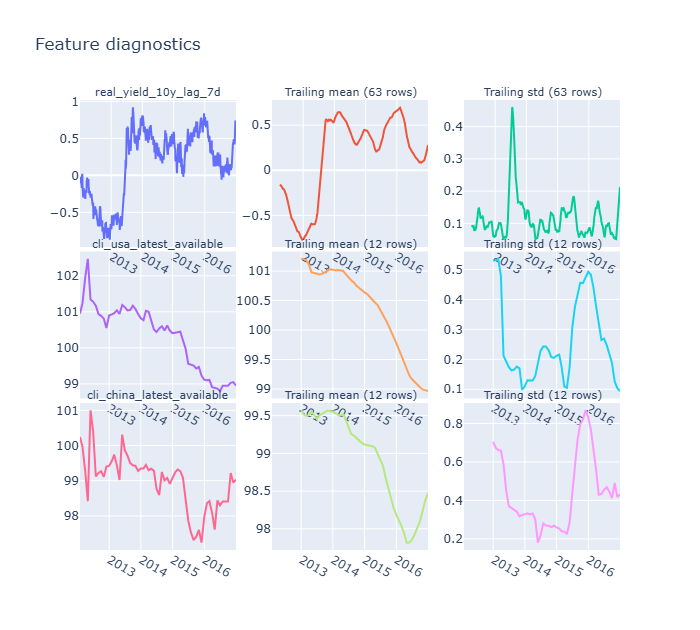

In [6]:
fig = dc.plot_feature_diagnostics(macro_data1)
fig.show()

In [7]:
adf_results = dc.adf_summary(macro_data1, regression="c")
adf_results[["frequency", "n_values", "adf_statistic", "p_value", "reject_unit_root"]]

,frequency,n_values,adf_statistic,p_value,reject_unit_root
feature,,,,,
real_yield_10y_lag_7d,session,1258,-1.623655,0.470814,False
cli_usa_latest_available,month_end,60,-0.522035,0.887644,False
cli_china_latest_available,month_end,60,-3.047107,0.030723,True


### Conclusion and representation policy

The yield level and USA CLI level do not reject the unit-root null in Data1; China CLI rejects it. Following Tsay's framework, first differences are useful alternative representations of persistent levels.

However, an ADF result is not a requirement to discard a level feature. Levels describe the economic environment; changes describe its direction. We therefore **retain all three macro levels and add changes**. Both CLI indices receive the same monthly-change representation because they measure the same economic concept and their short diagnostic samples do not justify different country-specific rules.

## 4 - Add macro changes and save development data

In [8]:
features = dc.add_macro_changes(initial_features)
features = features.loc["2012-01-01":]

features.info()
features.tail()

<class 'pandas.DataFrame'>
DatetimeIndex: 2768 entries, 2012-01-03 to 2022-12-30
Data columns (total 19 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   copper_ret1d                         2768 non-null   float64
 1   copper_ret5d                         2768 non-null   float64
 2   gold_ret1d                           2768 non-null   float64
 3   gold_ret5d                           2768 non-null   float64
 4   crude_ret1d                          2768 non-null   float64
 5   crude_ret5d                          2768 non-null   float64
 6   sp500_ret1d                          2768 non-null   float64
 7   sp500_ret5d                          2768 non-null   float64
 8   dxy_ret1d                            2768 non-null   float64
 9   dxy_ret5d                            2768 non-null   float64
 10  USDCNY_ret1d                         2768 non-null   float64
 11  USDCNY_ret5d           

,copper_ret1d,copper_ret5d,gold_ret1d,gold_ret5d,crude_ret1d,crude_ret5d,sp500_ret1d,sp500_ret5d,dxy_ret1d,dxy_ret5d,USDCNY_ret1d,USDCNY_ret5d,copper_vol21d,real_yield_10y_lag_7d,cli_usa_latest_available,cli_china_latest_available,real_yield_10y_lag_7d_change1d,cli_usa_latest_available_change1m,cli_china_latest_available_change1m
date,,,,,,,,,,,,,,,,,,,
2022-12-23,0.014414,0.012217,0.002994,0.002814,0.023647,0.065886,0.005851,-0.001959,-0.001150,-0.003732,0.000344,0.001548,0.214898,1.35,98.51,98.74,0.07,0.03,0.27
2022-12-27,-0.001736,0.012678,0.008395,0.014030,0.003025,0.051044,-0.004058,0.003031,-0.001247,-0.005170,-0.003127,-0.001565,0.212865,1.45,98.51,98.74,0.10,0.03,0.27
2022-12-28,0.006063,0.006063,-0.004516,-0.006944,-0.013757,0.035018,-0.012093,-0.010099,0.002684,0.004702,-0.000316,-0.002813,0.211093,1.41,98.51,98.74,-0.04,0.03,0.27
2022-12-29,0.000000,0.003894,0.005583,0.000296,-0.000729,0.006882,0.017311,-0.007547,-0.005953,-0.003077,0.002669,0.002411,0.207078,1.48,98.51,98.74,0.07,0.03,0.27
2022-12-30,-0.003027,0.015714,0.004668,0.017123,0.022794,0.034979,-0.002544,0.004466,-0.003086,-0.008752,-0.002080,-0.002510,0.167371,1.55,98.51,98.74,0.07,0.03,0.27


In [9]:
from dr_copper_v2.data_loader import ROOT

data_dir = ROOT / "data" / "processed"
data_dir.mkdir(parents=True, exist_ok=True)

raw.to_parquet(data_dir / "raw_development.parquet")
features.to_parquet(data_dir / "features_development.parquet")

## 5 - Monthly walk-forward split

Each fold uses all earlier feature rows for training and the next calendar month for evaluation. The first training window is Data1 (2012-2016); Data2 supplies 72 monthly evaluation blocks. Later folds include previous Data2 months in training.

In [10]:
import pandas as pd

split_rows = []
for train, test in dc.walk_forward_split(features):
    split_rows.append(
        {
            "train_start": train.index.min(),
            "train_end": train.index.max(),
            "test_start": test.index.min(),
            "test_end": test.index.max(),
            "train_rows": len(train),
            "test_rows": len(test),
        }
    )

splits = pd.DataFrame(split_rows)
print(f"Monthly folds: {len(splits)}")
splits.iloc[[0, -1]]

Monthly folds: 72


,train_start,train_end,test_start,test_end,train_rows,test_rows
0,2012-01-03,2016-12-30,2017-01-03,2017-01-31,1258,20
71,2012-01-03,2022-11-30,2022-12-01,2022-12-30,2747,21


## 6 - PCA: first fold

In [11]:
train, test = next(dc.walk_forward_split(features))
pipe, loadings, train_scores, evr = dc.fit_pca(train)
test_scores = dc.transform_pca(test, pipe)

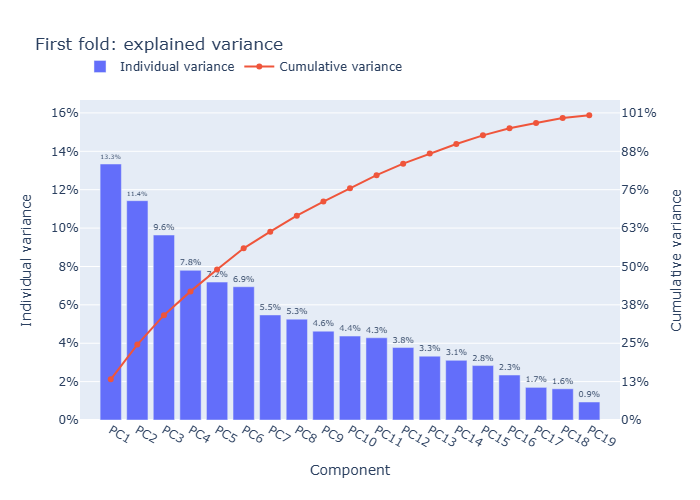

In [12]:
import plotly.express as px
import plotly.graph_objects as go

fig = go.Figure(
    go.Bar(
        x=evr.index,
        y=evr,
        name="Individual variance",
        text=evr,
        texttemplate="%{text:.1%}",
        textposition="outside",
    )
)
fig.add_scatter(
    x=evr.index,
    y=evr.cumsum(),
    name="Cumulative variance",
    mode="lines+markers",
    yaxis="y2",
)
fig.update_layout(
    title="First fold: explained variance",
    xaxis_title="Component",
    yaxis=dict(
        title="Individual variance", tickformat=".0%", range=[0, evr.max() * 1.25]
    ),
    yaxis2=dict(
        title="Cumulative variance",
        tickformat=".0%",
        range=[0, 1.05],
        overlaying="y",
        side="right",
        showgrid=False,
    ),
    legend=dict(orientation="h", y=1.15),
)
fig.show()

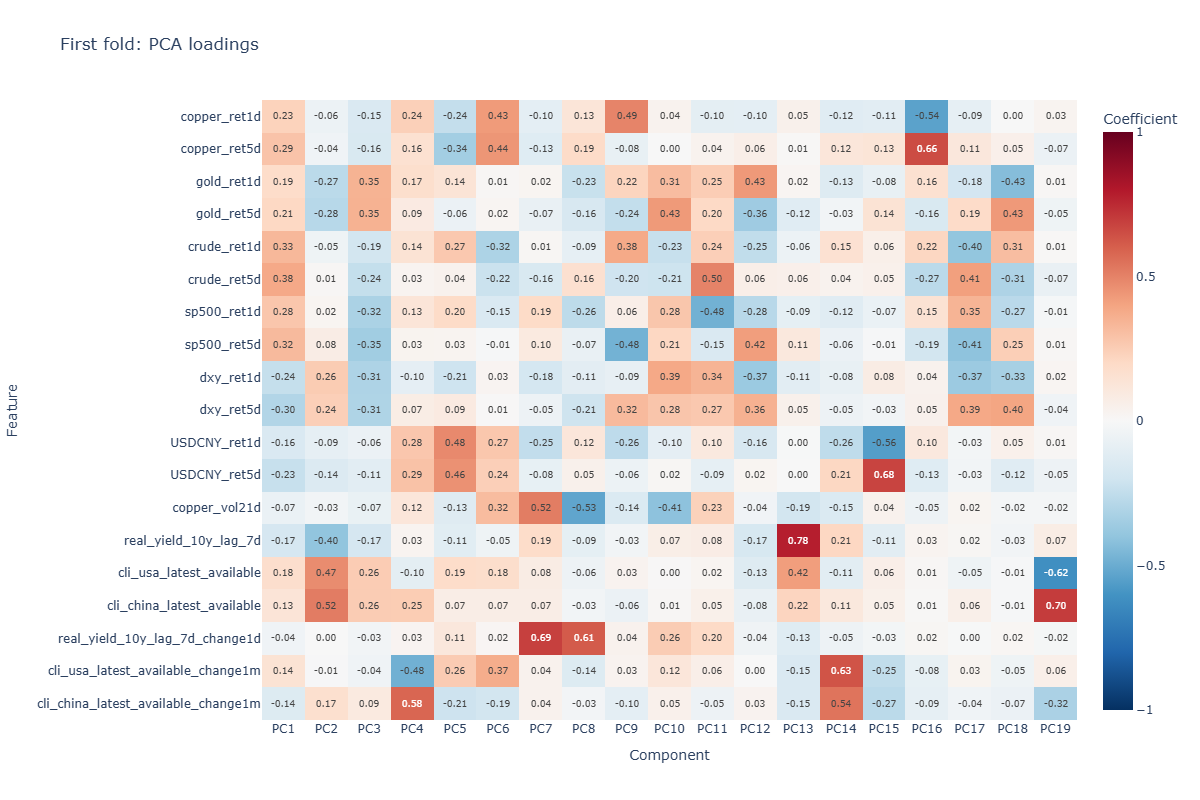

In [13]:
fig = px.imshow(
    loadings,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    aspect="auto",
    title="First fold: PCA loadings",
    height=800,
    width=1200,
    labels={"x": "Component", "y": "Feature", "color": "Coefficient"},
)
fig.update_traces(textfont_size=9)
fig.update_xaxes(tickmode="linear")
fig.show()

## 7 - PCA explained variance across monthly folds

The summary shows how many PCs are needed for 80%, 90% and 95% of training variance across the 72 development fits.

In [14]:
variance_by_fold = {}
loadings_by_fold = {}
scales_by_fold = {}
for train, test in dc.walk_forward_split(features):
    fold = str(test.index.min().to_period("M"))
    fold_pipe, fold_loadings, fold_scores, fold_evr = dc.fit_pca(train)
    variance_by_fold[fold] = fold_evr
    loadings_by_fold[fold] = fold_loadings
    scales_by_fold[fold] = fold_pipe.named_steps["scaler"].scale_

variance = pd.DataFrame.from_dict(variance_by_fold, orient="index")
variance.index.name = "fold"
cumulative_variance = variance.cumsum(axis=1)
print(f"PCA fits: {len(variance)}")

PCA fits: 72


In [15]:
components_needed = pd.DataFrame(
    {
        f"PCs for {threshold:.0%}": (cumulative_variance < threshold).sum(axis=1) + 1
        for threshold in [0.80, 0.90, 0.95]
    }
)
components_needed.agg(["min", "median", "max"])

,PCs for 80%,PCs for 90%,PCs for 95%
min,11.0,14.0,16.0
median,12.0,14.0,16.0
max,12.0,15.0,17.0


## 8 - Loading stability

Compare component directions after expressing them in the first fold's feature units. Match all components one-to-one by absolute cosine similarity: 1 means the same direction, allowing a sign flip; lower values mean a different direction.

Show both successive-month similarity and similarity to the first fit. The former can be high despite gradual drift. Each row refers to the reference fit's PC rank, not a permanent component identity. Close eigenvalues can produce rotating components even when their joint subspace is similar; future stability is not guaranteed.

In [16]:
fold_names = list(loadings_by_fold)
first_fold = fold_names[0]
common_loadings = {
    fold: loadings_by_fold[fold]
    .div(scales_by_fold[fold], axis=0)
    .mul(scales_by_fold[first_fold], axis=0)
    for fold in fold_names
}

monthly_matches = {}
initial_matches = {}
for previous_fold, fold in zip(fold_names[:-1], fold_names[1:], strict=True):
    monthly_matches[fold] = dc.compare_loadings(
        common_loadings[previous_fold], common_loadings[fold]
    )
    initial_matches[fold] = dc.compare_loadings(
        common_loadings[first_fold], common_loadings[fold]
    )

monthly_stability = pd.concat(monthly_matches, names=["fold", "component"])
initial_stability = pd.concat(initial_matches, names=["fold", "component"])

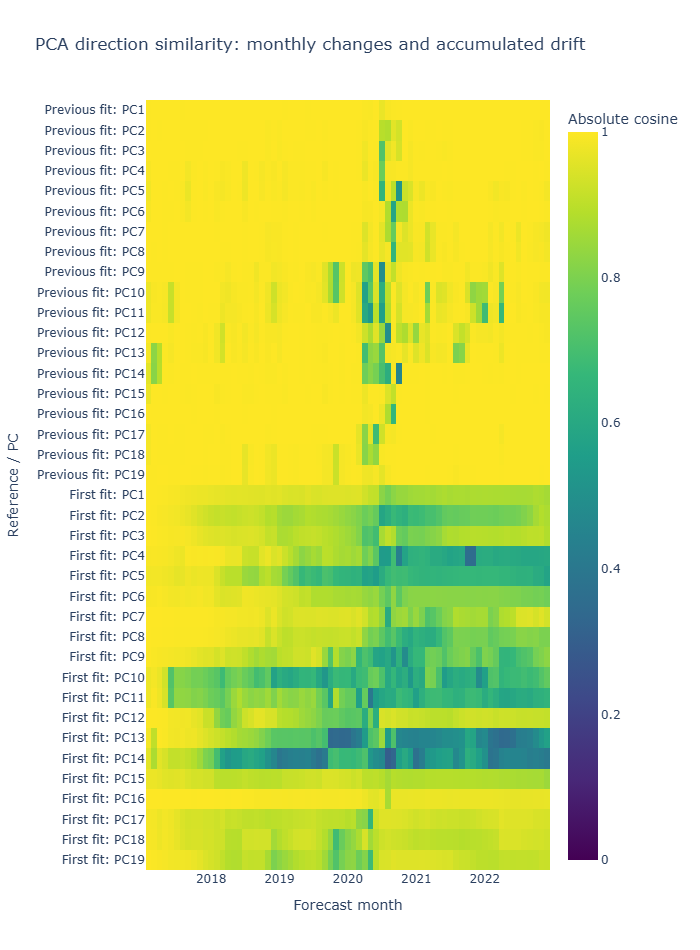

In [17]:
monthly_similarity = monthly_stability.similarity.unstack().reindex(columns=evr.index)
initial_similarity = initial_stability.similarity.unstack().reindex(columns=evr.index)

stability_plot = pd.concat(
    {"Previous fit": monthly_similarity.T, "First fit": initial_similarity.T}
)
stability_plot.index = [f"{reference}: {pc}" for reference, pc in stability_plot.index]

fig = px.imshow(
    stability_plot,
    zmin=0,
    zmax=1,
    color_continuous_scale="Viridis",
    aspect="auto",
    height=950,
    title="PCA direction similarity: monthly changes and accumulated drift",
    labels={"color": "Absolute cosine", "x": "Forecast month", "y": "Reference / PC"},
)
fig.show()

### PCA conclusion

PCA offers moderate compression: 80% of training variance requires 11-12 PCs across the development fits; 90% requires 14-15. We retain **12 components**, explaining approximately **82.5-84.8%** across these fits.

Stability varies by component rather than declining with variance rank. First-to-last similarity is 0.86-0.88 for PC1-PC3 and 0.92-0.97 for PC16-PC19; some intermediate directions change much more (for example, PC14 is about 0.40).

## 9 - Save fold-specific PCA features

Refit each training window with 12 PCs and transform its evaluation month.

In [18]:
import joblib

N_COMPONENTS = 12
pca_dir = data_dir / "pca" / f"n_components_{N_COMPONENTS}"
pca_dir.mkdir(parents=True, exist_ok=True)

for train, test in dc.walk_forward_split(features):
    fold = str(test.index.min().to_period("M"))
    fold_pipe, fold_loadings, train_scores, fold_evr = dc.fit_pca(train, N_COMPONENTS)
    test_scores = dc.transform_pca(test, fold_pipe)

    fold_dir = pca_dir / fold
    fold_dir.mkdir(exist_ok=True)
    joblib.dump(fold_pipe, fold_dir / "pipeline.joblib")
    train_scores.to_parquet(fold_dir / "train_scores.parquet")
    test_scores.to_parquet(fold_dir / "test_scores.parquet")

splits.to_parquet(pca_dir / "splits.parquet")
print(f"Saved {len(splits)} folds with {N_COMPONENTS} PCs each.")

Saved 72 folds with 12 PCs each.


## 10 - KMeans: choose the number of groups

Compare 2-6 clusters across the 72 training windows. Inertia per row describes within-cluster spread (lower is better, but adding clusters always reduces it). Silhouette describes separation (higher is better); it uses a reproducible sample of at most 500 training rows. Also inspect the smallest training group's share.

In [19]:
cluster_diagnostics = {}
for fold in fold_names:
    scores = pd.read_parquet(pca_dir / fold / "train_scores.parquet")
    cluster_diagnostics[fold] = dc.regime_diagnostics(scores)

cluster_diagnostics = pd.concat(cluster_diagnostics, names=["fold", "k"])
cluster_comparison = cluster_diagnostics.groupby("k").agg(
    median_inertia=("inertia_per_row", "median"),
    median_silhouette=("silhouette", "median"),
    min_silhouette=("silhouette", "min"),
    median_smallest_share=("smallest_share", "median"),
    min_smallest_share=("smallest_share", "min"),
)
cluster_comparison.round(3)

,median_inertia,median_silhouette,min_silhouette,median_smallest_share,min_smallest_share
k,,,,,
2,14.271,0.109,0.088,0.444,0.373
3,13.357,0.101,0.075,0.234,0.009
4,12.491,0.108,0.080,0.020,0.008
5,11.718,0.107,0.088,0.017,0.008
6,10.992,0.112,0.090,0.015,0.008


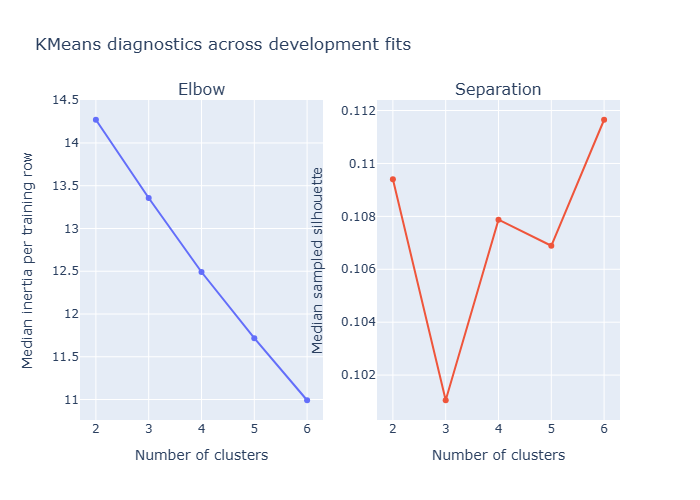

In [20]:
from plotly.subplots import make_subplots

fig = make_subplots(rows=1, cols=2, subplot_titles=["Elbow", "Separation"])
fig.add_trace(
    go.Scatter(
        x=cluster_comparison.index,
        y=cluster_comparison.median_inertia,
        mode="lines+markers",
    ),
    row=1,
    col=1,
)
fig.add_trace(
    go.Scatter(
        x=cluster_comparison.index,
        y=cluster_comparison.median_silhouette,
        mode="lines+markers",
    ),
    row=1,
    col=2,
)
fig.update_xaxes(title="Number of clusters", dtick=1)
fig.update_yaxes(title="Median inertia per training row", row=1, col=1)
fig.update_yaxes(title="Median sampled silhouette", row=1, col=2)
fig.update_layout(title="KMeans diagnostics across development fits", showlegend=False)
fig.show()

### Cluster-count choice

Silhouette scores are low (development medians about 0.10-0.11), so separation is weak. There is no compelling elbow. Counts 3-6 produce a very small group in some fits (under 1% of training rows), while two groups each retain at least about 37% across these fits. We choose **two exploratory groups** for simplicity and adequate group sizes, not because two groups clearly maximize separation or predict returns best.


## 11 - Monthly KMeans fits and saving

In [21]:
N_REGIMES = 2
regimes_dir = pca_dir / f"kmeans_{N_REGIMES}"
regimes_dir.mkdir(exist_ok=True)

for fold in fold_names:
    train_scores = pd.read_parquet(pca_dir / fold / "train_scores.parquet")
    test_scores = pd.read_parquet(pca_dir / fold / "test_scores.parquet")
    labels, km, _ = dc.fit_regimes(train_scores, N_REGIMES)
    assigned = dc.predict_regimes(test_scores, km)

    folder = regimes_dir / fold
    folder.mkdir(exist_ok=True)
    joblib.dump(km, folder / "kmeans.joblib")
    labels.to_frame().to_parquet(folder / "train_labels.parquet")
    assigned.to_frame().to_parquet(folder / "test_labels.parquet")

cluster_diagnostics.to_parquet(regimes_dir / "diagnostics.parquet")
print(f"Saved {len(fold_names)} KMeans fits with {N_REGIMES} groups.")

Saved 72 KMeans fits with 2 groups.
